In [1]:
import numpy as np
import pandas as pd

from black_scholes import bsm_price, bsm_delta
from hedging_engine import run_delta_hedging
from processes import simulate_gbm, simulate_merton_jump_diffusion
from metrics import summarize_pnl
from plots.PnL_plots import plot_pnl

In [2]:
bsm_price(100, 100, 1, 0.2, 10)

np.float64(99.99546000702375)

In [3]:
seed = 42
K = 100.0
T = 1.0
r = 0.05
sigma = 0.20
N = 1008

In [4]:
S = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=12)
N = S.shape[1] - 1

In [5]:
seeds = [1, 5, 7, 42, 144, 44, 424, 34]

for i in seeds:
    S = simulate_gbm(S0=100.0, mu=0.08, sigma=sigma, T=T, N=N, M=10_000, seed=i)
    N = S.shape[1] - 1
    pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
    print(f"seed: {i}, mean p&l: {np.mean(pnl)}, standard deviation of p&l: {np.std(pnl)}")

seed: 1, mean p&l: -0.3494224574770815, standard deviation of p&l: 0.989567506872942
seed: 5, mean p&l: -0.35473284873102723, standard deviation of p&l: 0.9827900466269813
seed: 7, mean p&l: -0.35734128121936065, standard deviation of p&l: 0.9887380776723783
seed: 42, mean p&l: -0.34320989880950303, standard deviation of p&l: 0.9959210827494978
seed: 144, mean p&l: -0.3556388139502444, standard deviation of p&l: 0.9842087331164668
seed: 44, mean p&l: -0.36971619144867884, standard deviation of p&l: 1.0057153722998748
seed: 424, mean p&l: -0.3632879804766315, standard deviation of p&l: 0.9939377521979434
seed: 34, mean p&l: -0.3542695697062331, standard deviation of p&l: 0.9775806865139045


In [6]:
pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
print(pnl)

[-0.14576484 -0.72338067 -0.10644903 ...  0.5461154  -0.19001678
 -0.9611354 ]


In [7]:
pnl = run_delta_hedging(S=S, K=K, T=T, sigma=sigma, r=r)
summarize_pnl(pnl)

{'mean p&l': -0.3542695697062331,
 'std of p&l': 0.9775806865139045,
 'median of p&l': -0.321797292301639,
 'skewness': -0.2341441526724929,
 'excess kurtosis': 1.4423912165642694,
 'VaR_95': -2.010552095207621,
 'CVaR_95': -2.617572797149132}

In [8]:
params_common = dict(S0=100.0, mu=0.08, sigma=0.20, T=1.0, M=5000, N=252, seed=42)
hedge_params = dict(K=100.0, T=1.0, sigma=0.20, r=0.05)

S_gbm = simulate_gbm(**params_common)
S_merton_mod = simulate_merton_jump_diffusion(
    **params_common, lam=3.0, mu_j=-0.02, delta=0.05
)
S_merton_stress = simulate_merton_jump_diffusion(
    **params_common, lam=5.0, mu_j=-0.05, delta=0.10
)

pnl_gbm = run_delta_hedging(S=S_gbm, **hedge_params)
pnl_merton_mod = run_delta_hedging(S=S_merton_mod, **hedge_params)
pnl_merton_stress = run_delta_hedging(S=S_merton_stress, **hedge_params)

df_compare = pd.DataFrame({
    "GBM": summarize_pnl(pnl_gbm),
    "Merton (moderate)": summarize_pnl(pnl_merton_mod),
    "Merton (stress)": summarize_pnl(pnl_merton_stress),
}).T

print(df_compare)

                   mean p&l  std of p&l  median of p&l  skewness  \
GBM               -0.204339    1.914976      -0.213769 -0.375639   
Merton (moderate) -1.019295    2.320452      -0.824639 -0.970779   
Merton (stress)   -4.871151    4.773904      -3.661324 -1.517261   

                   excess kurtosis     VaR_95    CVaR_95  
GBM                       1.874854  -3.375744  -4.647974  
Merton (moderate)         3.035739  -5.190133  -7.164172  
Merton (stress)           3.542611 -14.268901 -18.404397  


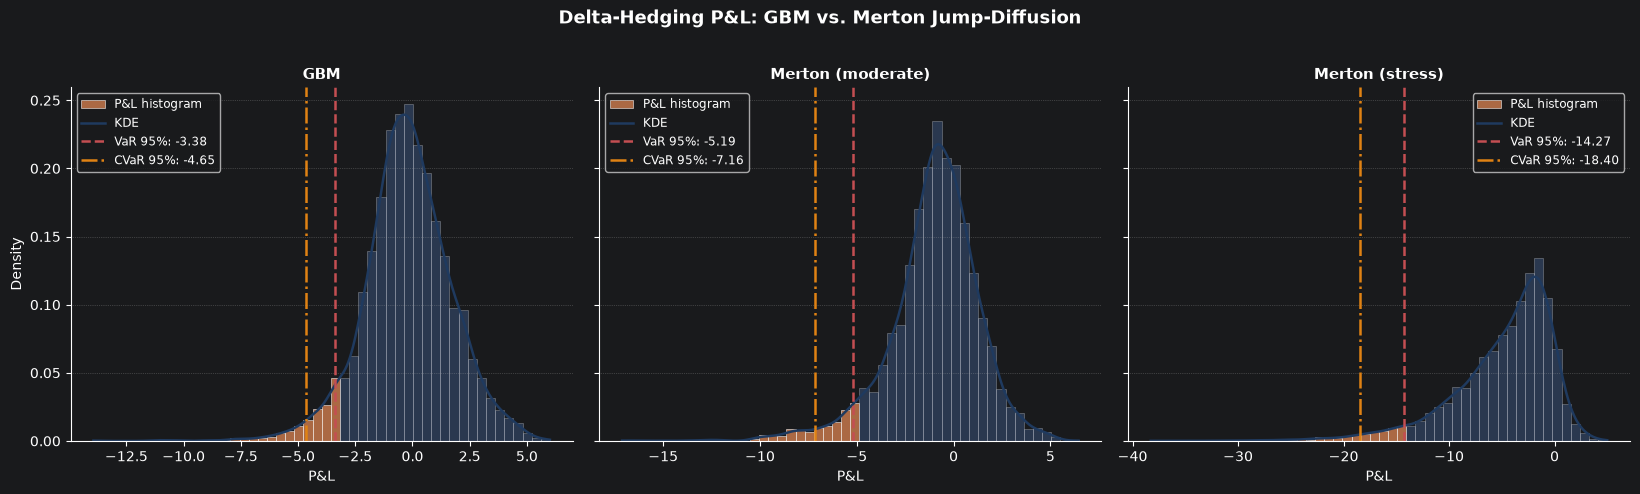

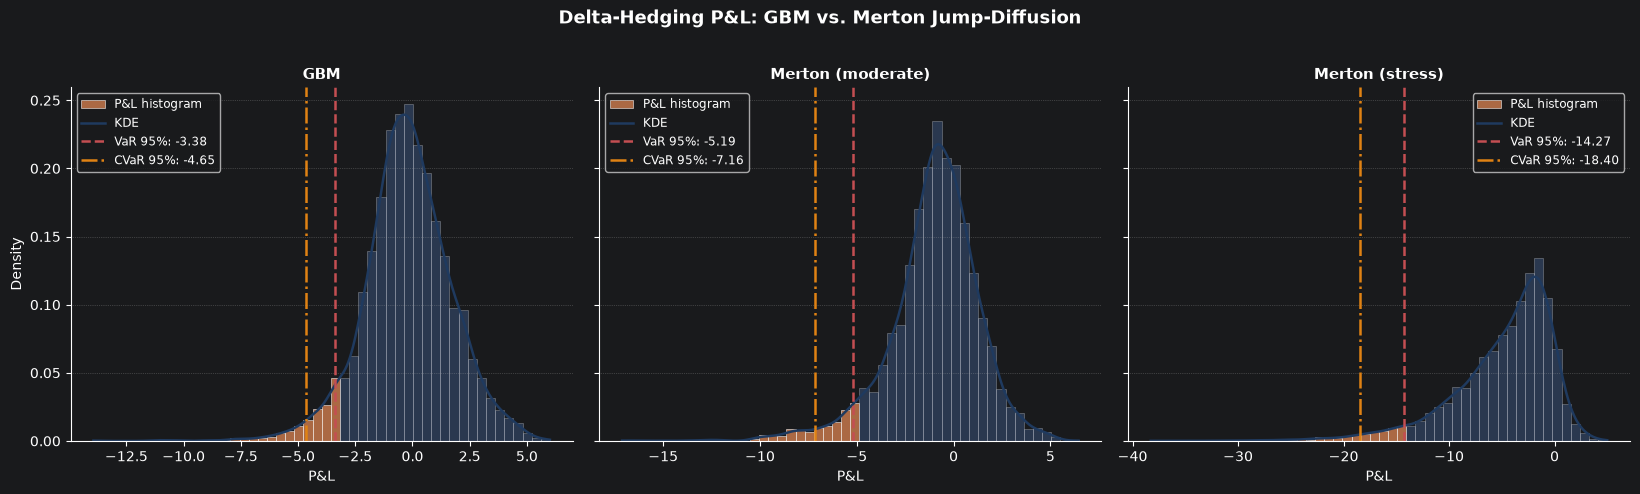

In [10]:
from plots.PnL_plots import plot_pnl_comparison

plot_pnl_comparison({
    "GBM": pnl_gbm,
    "Merton (moderate)": pnl_merton_mod,
    "Merton (stress)": pnl_merton_stress,
})